In [1]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [9]:
import pandas as pd

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [15]:
# 1 - Inspect the dataset

print("1. Dataset Shape:")
print(df.shape)

print("\n2. Dataset Information:")
df.info()

print("\n3. Missing Values:")
print(df.isnull().sum())

print("\n4. Duplicate Rows:")
print(df.duplicated().sum())

print("\n5. Statistical Summary:")
df.describe(include="all")


1. Dataset Shape:
(7043, 21)

2. Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   o

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043.000000,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,NaN,2
top,3186-AJIEK,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,NaN,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,NaN,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,2279.734304,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,2266.794470,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,0.000000,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,398.550000,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,1394.550000,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,3786.600000,NaN


In [16]:
# 2 - Clean TotalCharges
# Check the original data type
print("Before cleaning:", df["TotalCharges"].dtype)

# Convert the column to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

# Check missing values after conversion
print("After cleaning:", df["TotalCharges"].dtype)
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

# Display the affected rows
df[df["TotalCharges"].isnull()][["customerID", "tenure", "TotalCharges"]].head()


Before cleaning: float64
After cleaning: float64
Missing TotalCharges: 0


,customerID,tenure,TotalCharges


In [18]:
# Inspect rows with missing TotalCharges

missing_charges = df[df["TotalCharges"].isnull()]

print("Number of affected rows:", len(missing_charges))

display(
    missing_charges[
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)


Number of affected rows: 0


,customerID,tenure,MonthlyCharges,TotalCharges,Churn


In [13]:
# Handle missing TotalCharges for new customers

mask = df["TotalCharges"].isnull() & (df["tenure"] == 0)

print("Rows to update:", mask.sum())

df.loc[mask, "TotalCharges"] = 0

print("Remaining missing values:", df["TotalCharges"].isnull().sum())


Rows to update: 11
Remaining missing values: 0


In [19]:
# 3 - Check duplicate rows

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())


Duplicate rows: 0
Duplicate customer IDs: 0


Customer Churn Counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Customer Churn Percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


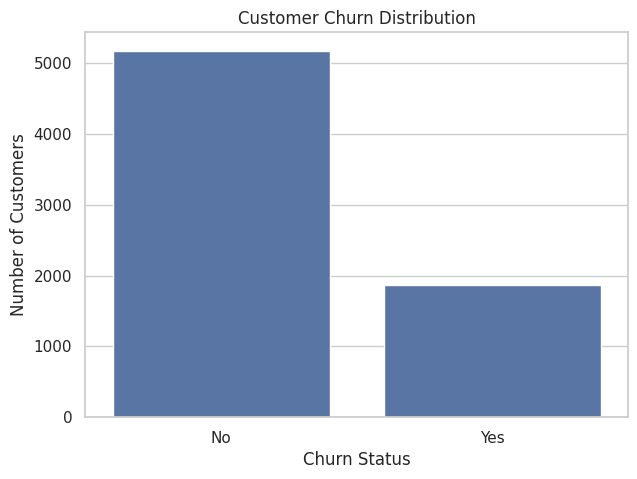

In [20]:
# 4 - Analyze customer churn
# Count customers in each category
churn_counts = df["Churn"].value_counts()

print("Customer Churn Counts:")
print(churn_counts)

# Calculate percentages
churn_percentages = df["Churn"].value_counts(normalize=True) * 100

print("\nCustomer Churn Percentages:")
print(churn_percentages.round(2))

# Visualize churn distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()


Churn Percentage by Contract Type:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


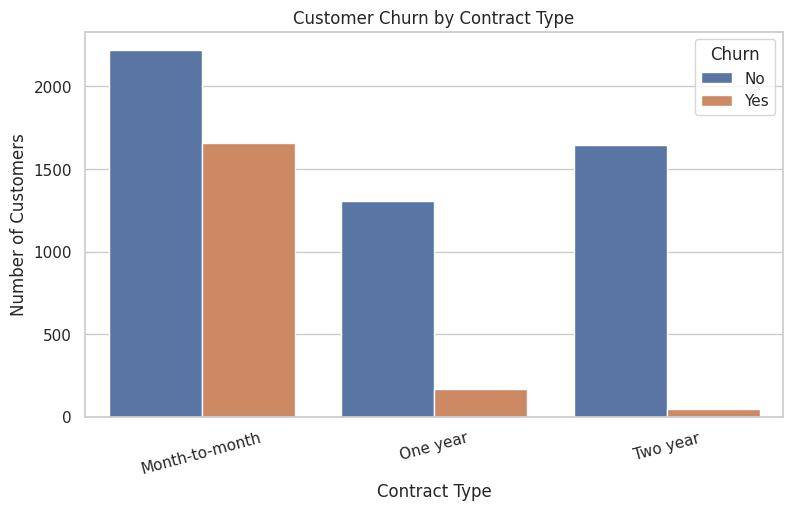

In [21]:

# 5 - Analyze churn by contract type
# تحليل المغادرة حسب نوع العقد

churn_by_contract = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Percentage by Contract Type:")
display(churn_by_contract.round(2))

# Visualize churn by contract type
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

plt.show()


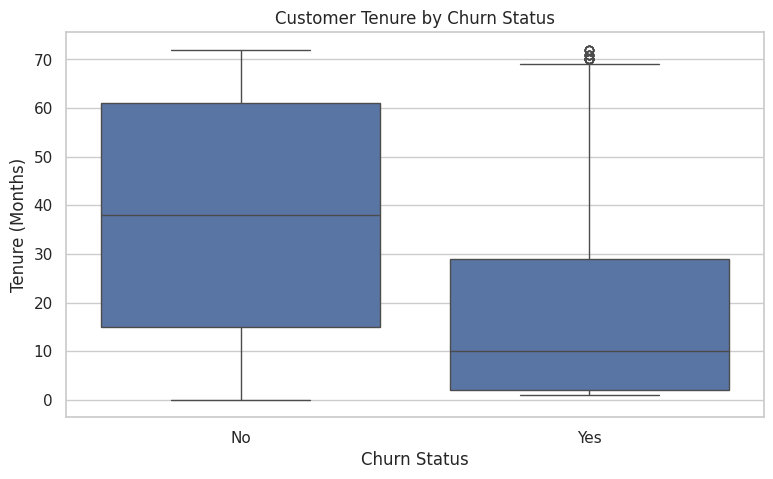

Average tenure by churn status:


,tenure
Churn,
No,37.57
Yes,17.98


In [23]:
# 6 - Analyze tenure and customer churn
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")

plt.show()

# Compare average tenure
print("Average tenure by churn status:")
display(
    df.groupby("Churn")["tenure"]
      .mean()
      .round(2)
)


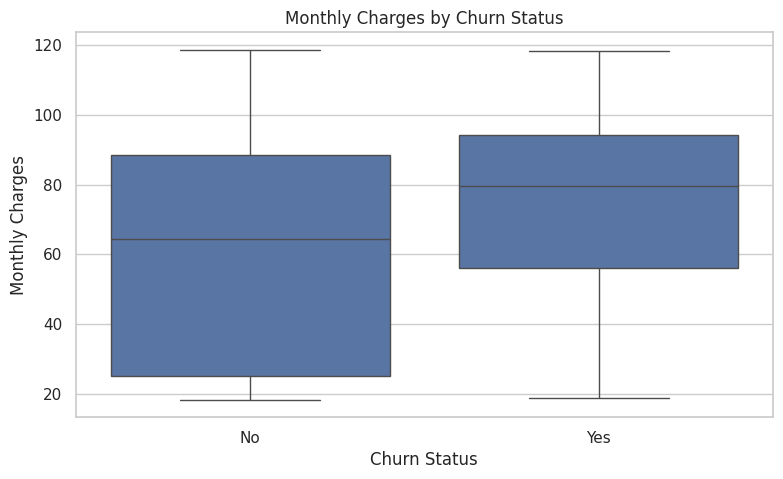

Average monthly charges by churn status:


,MonthlyCharges
Churn,
No,61.27
Yes,74.44


In [24]:
# 7 - Analyze monthly charges and churn
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")

plt.show()

# Compare average monthly charges
print("Average monthly charges by churn status:")

display(
    df.groupby("Churn")["MonthlyCharges"]
      .mean()
      .round(2)
)


In [25]:
# 8 - Create a summary of key findings
summary = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Overall Churn Rate (%)",
        "Average Tenure - Churned",
        "Average Tenure - Retained",
        "Average Monthly Charges - Churned",
        "Average Monthly Charges - Retained"
    ],
    "Value": [
        len(df),
        round((df["Churn"] == "Yes").mean() * 100, 2),
        round(df.loc[df["Churn"] == "Yes", "tenure"].mean(), 2),
        round(df.loc[df["Churn"] == "No", "tenure"].mean(), 2),
        round(df.loc[df["Churn"] == "Yes", "MonthlyCharges"].mean(), 2),
        round(df.loc[df["Churn"] == "No", "MonthlyCharges"].mean(), 2)
    ]
})

display(summary)


,Metric,Value
0,Total Customers,7043.00
1,Overall Churn Rate (%),26.54
2,Average Tenure - Churned,17.98
3,Average Tenure - Retained,37.57
4,Average Monthly Charges - Churned,74.44
5,Average Monthly Charges - Retained,61.27


In [26]:
# 9 - Export the summary table
summary.to_csv("customer_churn_summary.csv", index=False)

print("Summary exported successfully!")


Summary exported successfully!
